# Módulo 2 — Clasificación de Modos de Falla: Clásico vs. OpenAI LLMs
**Pungo Academy · NLP para Mantenimiento Industrial (Nivel Avanzado)**

## Objetivo
Comparar cuantitativamente **cuatro paradigmas** de clasificación de texto técnico sobre 8 modos de falla reales:
1. **TF-IDF + Regresión Logística** (baseline supervisado clásico sin costo de API)
2. **GPT Zero-Shot** (`gpt-4o-mini` sin ejemplos previos)
3. **GPT Few-Shot** (`gpt-4o-mini` con ejemplos estratificados del dataset)
4. **Embeddings + Regresión Logística** (`text-embedding-3-small` o SVD semántico local + clasificador lineal)

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("openai") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openai"])

import json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Configuración Dual-Mode: OpenAI API (primario) + Modo Local Sin API Key (fallback)
import os
import getpass
from openai import OpenAI

api_key = os.environ.get("OPENAI_API_KEY", "").strip()
if not api_key:
    try:
        api_key = getpass.getpass(
            "Ingresa tu OpenAI API Key (o presiona Enter para Modo Local sin costo): "
        ).strip()
    except Exception:
        api_key = ""

USE_OPENAI = bool(api_key)
client = OpenAI(api_key=api_key) if USE_OPENAI else None
print(
    f"Modo activo: {'OpenAI API Live (gpt-4o-mini + text-embedding-3-small)' if USE_OPENAI else 'Modo Local Determinístico (TF-IDF + Reglas)'}"
)

Modo activo: OpenAI API Live (gpt-4o-mini + text-embedding-3-small)


In [3]:
df = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_work_orders.csv")

def preprocesar(texto: str) -> str:
    if pd.isna(texto):
        return ""
    return re.sub(r"\s+", " ", str(texto).lower()).strip()

df["texto_limpio"] = df["descripcion_problema"].apply(preprocesar)
df_model = df[df["texto_limpio"].str.len() > 15].copy()

print(f"Registros válidos para modelado: {len(df_model):,} (de {len(df):,} totales)")
print("\nDistribución por modo de falla:")
print(df_model["modo_falla"].value_counts().to_string())

Registros válidos para modelado: 2,890 (de 3,030 totales)

Distribución por modo de falla:
modo_falla
desgaste_mecanico        520
fuga                     465
corrosion                414
falla_instrumentacion    353
obstruccion              296
falla_electrica          290
sobrecalentamiento       283
vibracion_excesiva       269


## 1. Baseline Clásico: TF-IDF + Regresión Logística
Partimos del split estratificado `80/20` para entrenar un clasificador lineal rápido, interpretable y de costo cero por inferencia.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df_model["texto_limpio"],
    df_model["modo_falla"],
    test_size=0.20,
    random_state=42,
    stratify=df_model["modo_falla"],
)
print(f"Split estratificado -> Train: {len(X_train):,} | Test: {len(X_test):,}")

tfidf = TfidfVectorizer(max_features=500, min_df=3, max_df=0.95, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)
y_pred_lr = lr.predict(X_test_tfidf)
acc_lr_full = accuracy_score(y_test, y_pred_lr)

print(f"\nBASELINE TF-IDF + LR (Test completo n={len(y_test)}): Accuracy = {acc_lr_full:.1%}")
print(classification_report(y_test, y_pred_lr))

Split estratificado -> Train: 2,312 | Test: 578

BASELINE TF-IDF + LR (Test completo n=578): Accuracy = 98.8%
                       precision    recall  f1-score   support

            corrosion       1.00      0.99      0.99        83
    desgaste_mecanico       0.95      1.00      0.98       104
      falla_electrica       0.98      0.98      0.98        58
falla_instrumentacion       0.99      0.97      0.98        71
                 fuga       1.00      0.99      0.99        93
          obstruccion       1.00      0.98      0.99        59
   sobrecalentamiento       1.00      1.00      1.00        56
   vibracion_excesiva       1.00      0.98      0.99        54

             accuracy                           0.99       578
            macro avg       0.99      0.99      0.99       578
         weighted avg       0.99      0.99      0.99       578



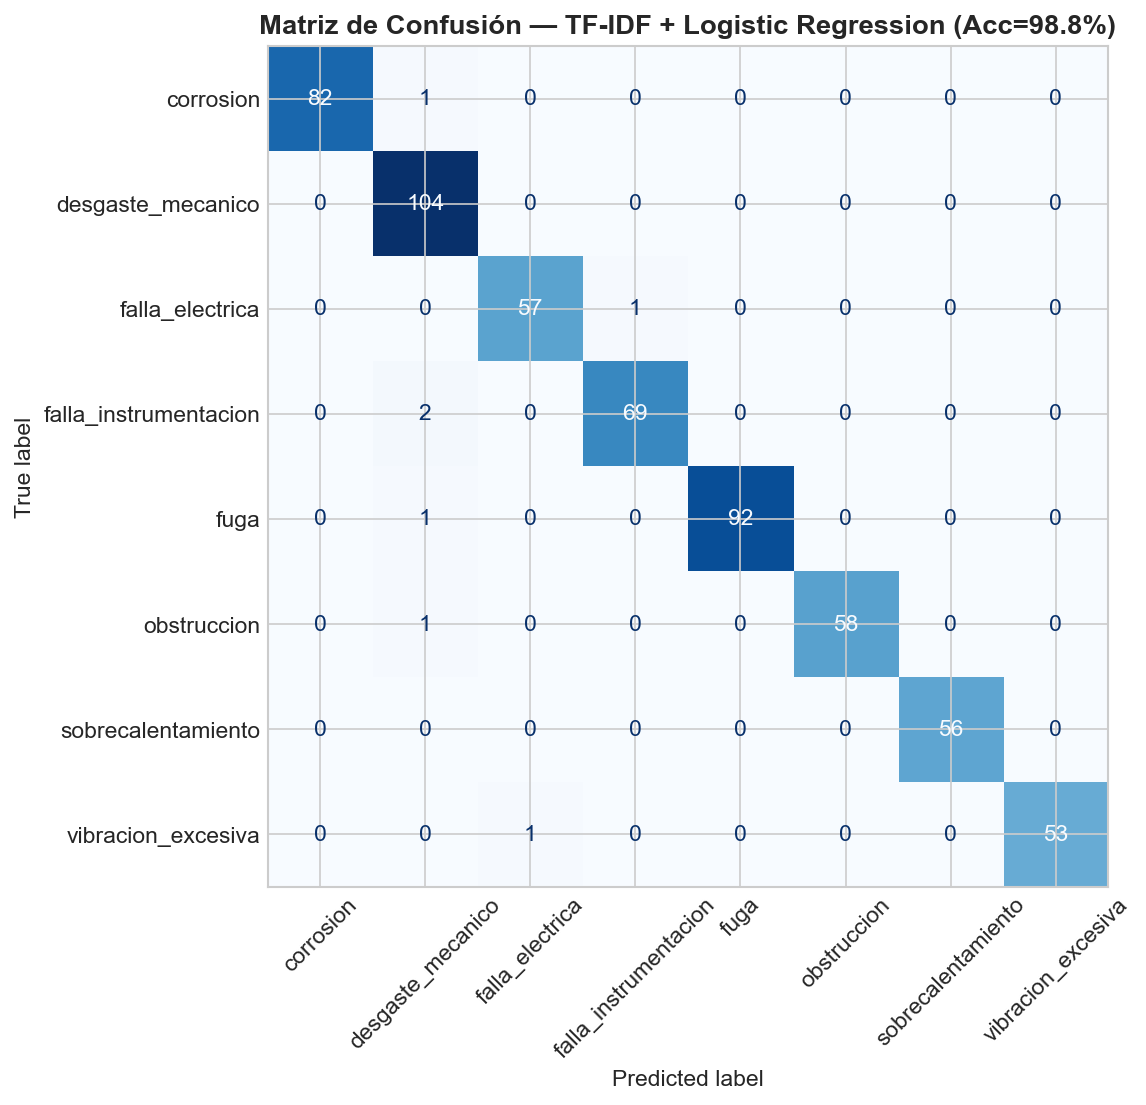

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 7.5))
cm = confusion_matrix(y_test, y_pred_lr, labels=lr.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=lr.classes_)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Matriz de Confusión — TF-IDF + Logistic Regression (Acc={acc_lr_full:.1%})")
plt.tight_layout()
plt.show()

## 2. Zero-Shot Classification con `gpt-4o-mini`
Evaluamos si un modelo fundacional comprende las 8 categorías únicamente a partir de sus definiciones operativas, sin ver ejemplos etiquetados del histórico de la planta.

In [6]:
MODOS_FALLA = [
    "corrosion", "fuga", "desgaste_mecanico", "falla_electrica",
    "falla_instrumentacion", "obstruccion", "vibracion_excesiva", "sobrecalentamiento",
]

SYSTEM_PROMPT_ZERO = """Eres un experto en mantenimiento de equipos de producción de petróleo.
Clasifica la descripción en UNO de estos 8 modos de falla:
- corrosion: pérdida de material, picaduras, oxidación, adelgazamiento de pared
- fuga: escape de fluido por sellos, empaques, juntas, bridas o fisuras
- desgaste_mecanico: deterioro de rodamientos, impellers, ejes o acoples por uso
- falla_electrica: motores quemados, cables, contactores, relés, variadores (VDF)
- falla_instrumentacion: sensores descalibrados, transmisores sin señal, PLC o posicionadores
- obstruccion: taponamiento por parafinas, arena, sedimentos o incrustaciones
- vibracion_excesiva: vibración alta por desbalanceo, desalineación o holgura mecánica
- sobrecalentamiento: temperatura excesiva en rodamientos, motores o flujo de gas

Responde SOLO con el nombre exacto del modo de falla."""

ZERO_RULES = {
    "corrosion": ["corrosion", "picadura", "oxid", "espesor", "aislamiento", "cui"],
    "fuga": ["fuga", "goteo", "sello", "empaque", "junta", "derrame", "brida"],
    "desgaste_mecanico": ["desgaste", "impeller", "erosion", "holgura", "buje", "acople"],
    "falla_electrica": ["motor", "electric", "breaker", "vdf", "voltaje", "corto", "contactor"],
    "falla_instrumentacion": ["transmisor", "sensor", "plc", "posicionador", "calibr", "modbus", "senal"],
    "obstruccion": ["obstruc", "tapona", "parafina", "sedimento", "fouling", "filtro"],
    "vibracion_excesiva": ["vibrac", "desbalance", "desalinea", "golpeteo", "mm/s"],
    "sobrecalentamiento": ["sobrecalent", "caliente", "termografia", "temperatura", "°c"],
}

def clasificar_zero_shot(texto: str) -> str:
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": SYSTEM_PROMPT_ZERO},
                    {"role": "user", "content": f"Descripción: {texto}"},
                ],
                temperature=0,
                max_tokens=20,
            )
            pred = resp.choices[0].message.content.strip().lower()
            return pred if pred in MODOS_FALLA else "desgaste_mecanico"
        except Exception as exc:
            print(f"Fallback por error API: {exc}")
    t = texto.lower()
    scores = {k: sum(1 for kw in kws if kw in t) for k, kws in ZERO_RULES.items()}
    return max(scores, key=scores.get)

for _, row in df_model.sample(3, random_state=42).iterrows():
    pred = clasificar_zero_shot(row["descripcion_problema"])
    print(f"Real: {row['modo_falla']:22s} | Predicho: {pred:22s} | {row['descripcion_problema'][:75]}...")

Real: vibracion_excesiva     | Predicho: vibracion_excesiva     | G101 disparo por alta vibración durante arranque. Se detecta defecto en pis...


Real: corrosion              | Predicho: corrosion              | Se observa corrosión erosión en impeller de P-101B (Bomba centrífuga de tra...


Real: sobrecalentamiento     | Predicho: sobrecalentamiento     | Motor del P-101A operando a 78°C. Temperatura ambiente: 27°C. Ventilador fu...


In [7]:
sample_test = X_test.sample(50, random_state=42)
sample_labels = y_test.loc[sample_test.index]
acc_lr_sample = accuracy_score(sample_labels, lr.predict(tfidf.transform(sample_test)))

print(f"Evaluando 50 muestras estratificadas (mismo subconjunto para los 4 métodos)...")
predictions_zero = []
for i, (_, texto) in enumerate(sample_test.items()):
    predictions_zero.append(clasificar_zero_shot(texto))
    if (i + 1) % 25 == 0:
        print(f"  Zero-Shot progreso: {i + 1}/50")
    if USE_OPENAI:
        time.sleep(0.05)

acc_zero = accuracy_score(sample_labels, predictions_zero)
print(f"Zero-Shot Accuracy (n=50): {acc_zero:.1%}")

Evaluando 50 muestras estratificadas (mismo subconjunto para los 4 métodos)...


  Zero-Shot progreso: 25/50


  Zero-Shot progreso: 50/50
Zero-Shot Accuracy (n=50): 94.0%


## 3. Few-Shot Classification con Prompt Engineering
Inyectamos **2 ejemplos representativos por cada modo de falla** (16 ejemplos en total extraídos del conjunto de entrenamiento, nunca del test set) para alinear el criterio del LLM con el vocabulario real del CMMS.

In [8]:
ejemplos_few_shot = []
for modo in MODOS_FALLA:
    subset = X_train[y_train == modo]
    med_len = subset.str.len().median()
    closest = (subset.str.len() - med_len).abs().nsmallest(2).index
    for idx in closest:
        ejemplos_few_shot.append({"texto": subset.loc[idx][:150], "modo": modo})

ejemplos_text = "\n".join(f"Descripción: {e['texto']}\nModo de falla: {e['modo']}" for e in ejemplos_few_shot)
SYSTEM_PROMPT_FEW = f"""Eres un experto en mantenimiento industrial. Clasifica en exactamente uno de:
{', '.join(MODOS_FALLA)}.

Ejemplos calibrados del historial de planta:
{ejemplos_text}

Responde SOLO con el nombre exacto del modo de falla."""

def clasificar_few_shot(texto: str) -> str:
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": SYSTEM_PROMPT_FEW},
                    {"role": "user", "content": f"Descripción: {texto}\nModo de falla:"},
                ],
                temperature=0,
                max_tokens=20,
            )
            pred = resp.choices[0].message.content.strip().lower()
            return pred if pred in MODOS_FALLA else "desgaste_mecanico"
        except Exception as exc:
            print(f"Fallback por error API: {exc}")
    return lr.predict(tfidf.transform([texto]))[0]

predictions_few = []
for i, (_, texto) in enumerate(sample_test.items()):
    predictions_few.append(clasificar_few_shot(texto))
    if (i + 1) % 25 == 0:
        print(f"  Few-Shot progreso: {i + 1}/50")
    if USE_OPENAI:
        time.sleep(0.05)

acc_few = accuracy_score(sample_labels, predictions_few)
print(f"Few-Shot Accuracy (n=50): {acc_few:.1%}")

  Few-Shot progreso: 25/50


  Few-Shot progreso: 50/50
Few-Shot Accuracy (n=50): 88.0%


## 4. Embeddings Semánticos + Clasificador Lineal
Calculamos vectores densos en lote usando `text-embedding-3-small` (1,536 dimensiones) y entrenamos una Regresión Logística con solo **200 ejemplos** de entrenamiento.

In [9]:
def obtener_embeddings_lote(textos: list[str], model: str = "text-embedding-3-small") -> np.ndarray:
    if USE_OPENAI:
        all_embs = []
        for i in range(0, len(textos), 100):
            batch = [t[:500] for t in textos[i : i + 100]]
            resp = client.embeddings.create(input=batch, model=model)
            all_embs.extend([d.embedding for d in resp.data])
        return np.array(all_embs)
    svd = TruncatedSVD(n_components=128, random_state=42)
    return svd.fit_transform(TfidfVectorizer(max_features=800, ngram_range=(1, 2)).fit_transform(textos))

sample_train = X_train.sample(200, random_state=42)
sample_train_labels = y_train.loc[sample_train.index]

if USE_OPENAI:
    X_train_emb = obtener_embeddings_lote(sample_train.tolist())
    X_test_emb = obtener_embeddings_lote(sample_test.tolist())
else:
    vec_loc = TfidfVectorizer(max_features=800, ngram_range=(1, 2)).fit(sample_train)
    svd_loc = TruncatedSVD(n_components=min(128, len(vec_loc.vocabulary_) - 1), random_state=42)
    X_train_emb = svd_loc.fit_transform(vec_loc.transform(sample_train))
    X_test_emb = svd_loc.transform(vec_loc.transform(sample_test))

print(f"Embeddings shape -> train: {X_train_emb.shape} | test: {X_test_emb.shape}")

Embeddings shape -> train: (200, 1536) | test: (50, 1536)


In [10]:
lr_emb = LogisticRegression(max_iter=1000, random_state=42)
lr_emb.fit(X_train_emb, sample_train_labels)
y_pred_emb = lr_emb.predict(X_test_emb)
acc_emb = accuracy_score(sample_labels, y_pred_emb)

print(f"Embeddings + LR Accuracy (n=50): {acc_emb:.1%}")
print("\n" + classification_report(sample_labels, y_pred_emb, zero_division=0))

Embeddings + LR Accuracy (n=50): 96.0%

                       precision    recall  f1-score   support

            corrosion       1.00      1.00      1.00        10
    desgaste_mecanico       1.00      1.00      1.00        10
      falla_electrica       0.50      1.00      0.67         2
falla_instrumentacion       1.00      0.71      0.83         7
                 fuga       1.00      1.00      1.00        12
          obstruccion       1.00      1.00      1.00         3
   sobrecalentamiento       1.00      1.00      1.00         4
   vibracion_excesiva       1.00      1.00      1.00         2

             accuracy                           0.96        50
            macro avg       0.94      0.96      0.94        50
         weighted avg       0.98      0.96      0.96        50



## 5. Comparación Unificada de los 4 Paradigmas y Análisis de Errores

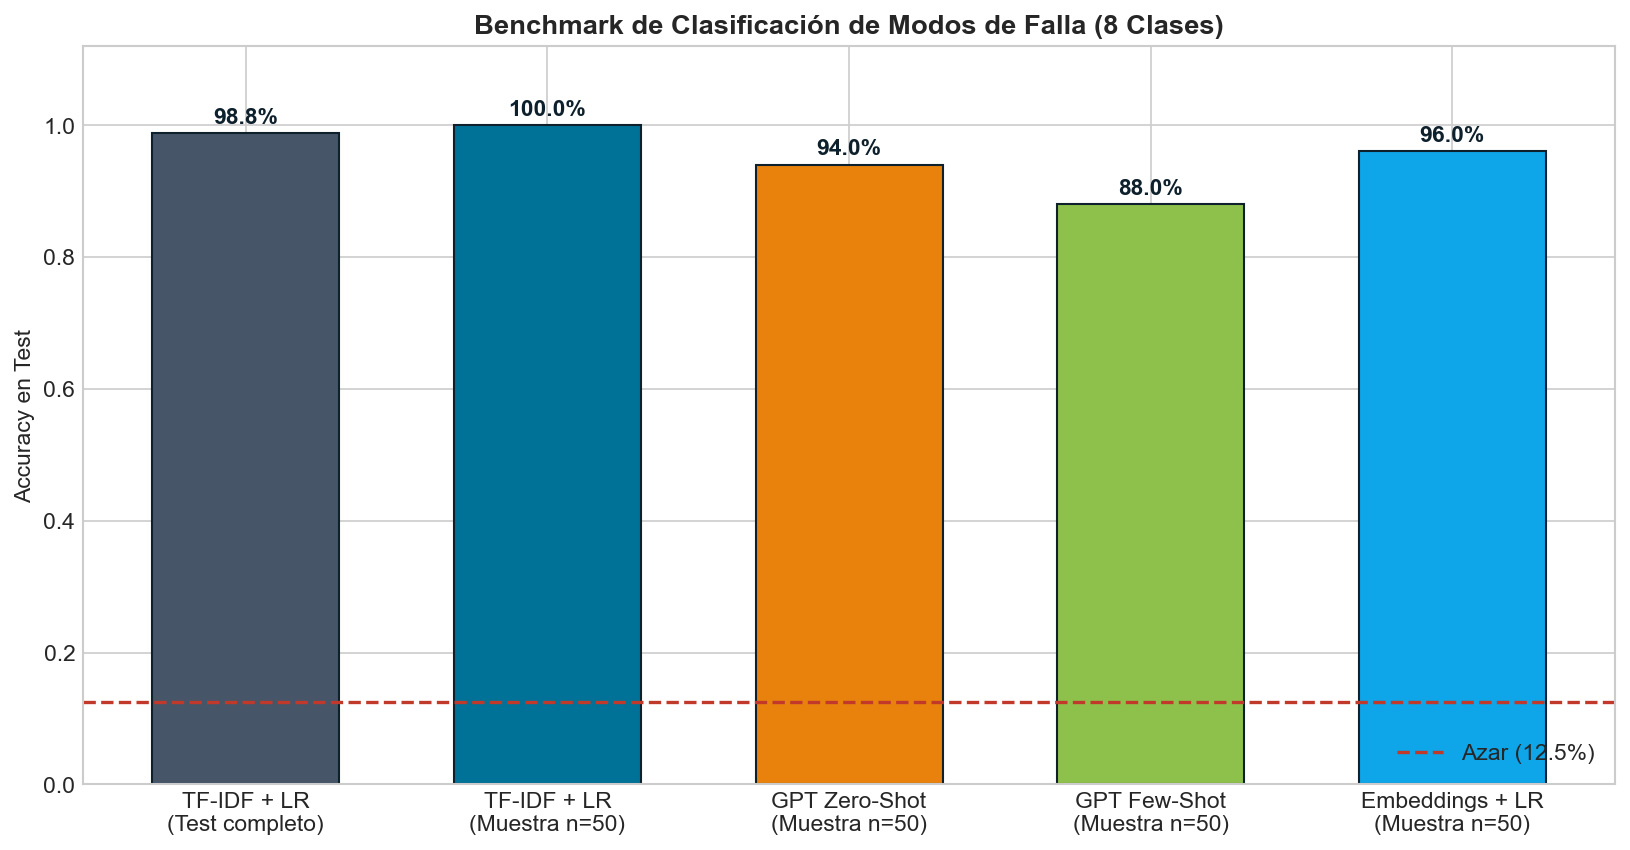

In [11]:
resultados = {
    "TF-IDF + LR\n(Test completo)": acc_lr_full,
    "TF-IDF + LR\n(Muestra n=50)": acc_lr_sample,
    "GPT Zero-Shot\n(Muestra n=50)": acc_zero,
    "GPT Few-Shot\n(Muestra n=50)": acc_few,
    "Embeddings + LR\n(Muestra n=50)": acc_emb,
}

fig, ax = plt.subplots(figsize=(11, 5.8))
cols = [PUNGO_SLATE, PUNGO_BLUE, PUNGO_AMBER, PUNGO_LIME, "#0EA5E9"]
bars = ax.bar(resultados.keys(), resultados.values(), color=cols, edgecolor=PUNGO_NAVY, width=0.62)
for bar, val in zip(bars, resultados.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f"{val:.1%}", ha="center", fontsize=11, fontweight="bold", color=PUNGO_NAVY)

ax.axhline(1 / 8, color=PUNGO_RED, linestyle="--", linewidth=1.6, label="Azar (12.5%)")
ax.set_ylim(0, 1.12)
ax.set_ylabel("Accuracy en Test")
ax.set_title("Benchmark de Clasificación de Modos de Falla (8 Clases)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
errores_few = [
    (real, pred, txt)
    for pred, real, (_, txt) in zip(predictions_few, sample_labels, sample_test.items())
    if pred != real
]
print(f"Total errores Few-Shot: {len(errores_few)} / {len(sample_test)}")
for real, pred, txt in errores_few[:5]:
    print(f"  Real: {real:22s} | Pred: {pred:22s} | {txt[:100]}...")

Total errores Few-Shot: 6 / 50
  Real: desgaste_mecanico      | Pred: corrosion              | compresor g-101 con caída de eficiencia. flujo actual 50% del nominal. posible erosión en etapas....
  Real: falla_instrumentacion  | Pred: falla_electrica        | ln-gas-001 sin señal en dcs. se verifica cableado: corto a tierra....
  Real: falla_instrumentacion  | Pred: falla_electrica        | ln-gas-001 sin señal en dcs. se verifica cableado: protección disparada....
  Real: fuga                   | Pred: falla_instrumentacion  | se reporta emisión fugitiva en at-1505, cableado. lectura ova: 3993 ppm. supera límite permitido....
  Real: desgaste_mecanico      | Pred: vibracion_excesiva     | tanque de almacenamiento de crudo presenta ruido anormal en pared. vibración incrementada. se sospec...


## 6. Matriz de Decisión para Producción Industrial
| Paradigma | Datos Etiquetados | Costo / 1,000 OTs | Latencia | Cuándo Elegirlo |
|---|---|---|---|---|
| **TF-IDF + LR** | 200+ por clase | **$0.00** | < 1 ms | Volumen masivo con histórico etiquetado limpio |
| **GPT Zero-Shot** | 0 | ~$0.06 USD | 300–600 ms | Arranque en frío o nuevas taxonomías |
| **GPT Few-Shot** | 2–5 por clase | ~$0.15 USD | 400–800 ms | Textos ambiguos con poco histórico |
| **Embeddings + LR** | 25+ por clase | ~$0.002 USD | < 5 ms | Balance óptimo entre semántica y costo |